# TTF Spot Settlement Exploratory Analysis

In [10]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from scipy import stats

sns.set_theme(
    context="paper",
    style="ticks",
    palette="colorblind",
    font_scale=1.05,
)
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "figure.figsize": (7.2, 4.4),
        "axes.labelsize": 10,
        "axes.titlesize": 11,
        "legend.fontsize": 8.5,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)


notebook_dir = Path.cwd()
data_path = notebook_dir.parent / "data/ttf spot/settlement/ttf_spot.parquet"
figure_dir = notebook_dir / "figures/ttf_spot_eda"
figure_dir.mkdir(parents=True, exist_ok=True)

spot = (
    pl.read_parquet(data_path)
    .with_columns(
        pl.col("TrdDate").str.to_date(),
        pl.col("DeliveryDay").str.to_date(),
    )
    .sort(["ShortCode", "TrdDate", "DeliveryDay"])
)

print(f"Rows: {spot.height:,}")
print(f"Trading dates: {spot['TrdDate'].min()} to {spot['TrdDate'].max()}")
print(f"Products: {', '.join(spot['ShortCode'].unique().sort().to_list())}")
print(f"Price units: {spot['Currency'][0]}/{spot['UOM'][0]}")

Rows: 1,450
Trading dates: 2022-01-04 to 2026-09-28
Products: TTFBH, TTFDA, TTFWE
Price units: EUR/MW


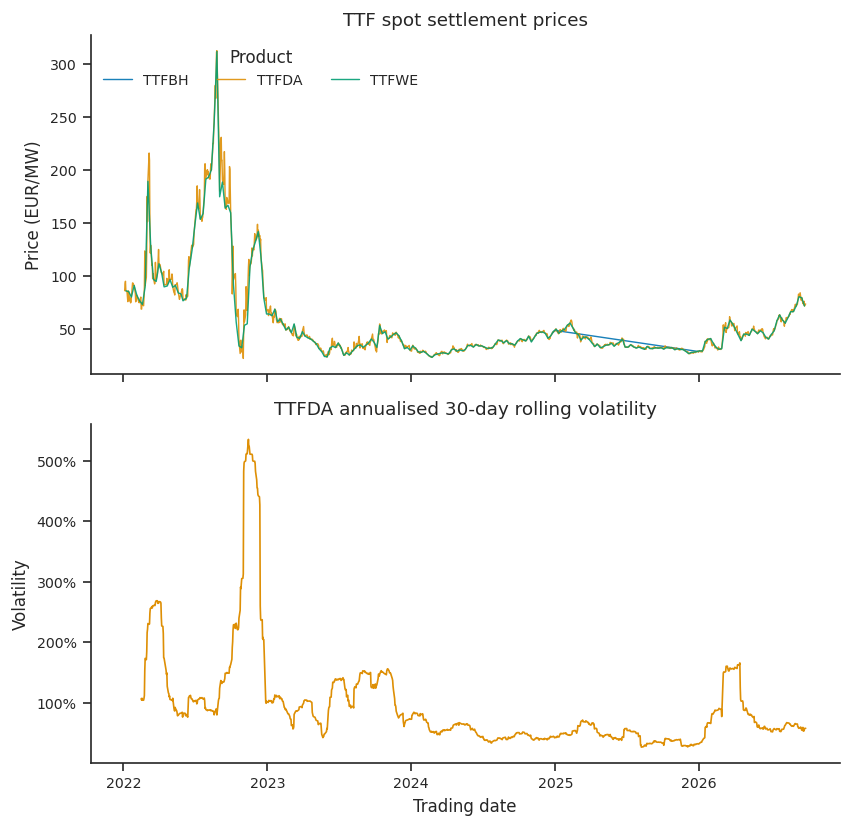

In [11]:
price_frame = spot.to_pandas()

fig, axes = plt.subplots(2, 1, figsize=(7.2, 7.0), sharex=True)

sns.lineplot(
    data=price_frame,
    x="TrdDate",
    y="Px",
    hue="ShortCode",
    linewidth=0.85,
    alpha=0.9,
    ax=axes[0],
)
axes[0].set_title("TTF spot settlement prices")
axes[0].set_xlabel("")
axes[0].set_ylabel("Price (EUR/MW)")
axes[0].legend(title="Product", frameon=False, ncol=3, loc="upper left")

benchmark = (
    price_frame.loc[price_frame["ShortCode"] == "TTFDA"]
    .sort_values("TrdDate")
    .drop_duplicates("TrdDate", keep="last")
    .copy()
)
benchmark["rolling_30d_volatility"] = benchmark["Px"].pct_change().rolling(
    30
).std() * np.sqrt(252)
sns.lineplot(
    data=benchmark,
    x="TrdDate",
    y="rolling_30d_volatility",
    color=sns.color_palette("colorblind")[1],
    linewidth=1.0,
    ax=axes[1],
)
axes[1].set_title("TTFDA annualised 30-day rolling volatility")
axes[1].set_xlabel("Trading date")
axes[1].set_ylabel("Volatility")
axes[1].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:.0%}")
)
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.tight_layout()
fig.savefig(figure_dir / "spot_prices_and_volatility.png", bbox_inches="tight")
plt.show()

In [12]:
returns = (
    benchmark[["TrdDate", "Px"]]
    .rename(columns={"Px": "price"})
    .assign(
        simple_return=lambda frame: frame["price"].pct_change(),
        log_return=lambda frame: np.log(frame["price"]).diff(),
    )
    .dropna(subset=["log_return"])
)

log_returns = returns["log_return"]
normal_reference = stats.norm(
    loc=log_returns.mean(), scale=log_returns.std(ddof=1)
)

summary = {
    "observations": len(log_returns),
    "mean": log_returns.mean(),
    "median": log_returns.median(),
    "std_dev": log_returns.std(ddof=1),
    "minimum": log_returns.min(),
    "maximum": log_returns.max(),
    "skewness": stats.skew(log_returns, bias=False),
    "excess_kurtosis": stats.kurtosis(log_returns, fisher=True, bias=False),
    "jarque_bera_p_value": stats.jarque_bera(log_returns).pvalue,
    "skewness_test_p_value": stats.skewtest(log_returns).pvalue,
    "kurtosis_test_p_value": stats.kurtosistest(log_returns).pvalue,
}

summary_frame = pl.DataFrame(
    {
        "Metric": [
            "Observations",
            "Mean",
            "Median",
            "Standard deviation",
            "Minimum",
            "Maximum",
            "Skewness",
            "Excess kurtosis",
            "Jarque-Bera p-value",
            "Skewness test p-value",
            "Kurtosis test p-value",
        ],
        "Value": [
            float(summary["observations"]),
            summary["mean"],
            summary["median"],
            summary["std_dev"],
            summary["minimum"],
            summary["maximum"],
            summary["skewness"],
            summary["excess_kurtosis"],
            summary["jarque_bera_p_value"],
            summary["skewness_test_p_value"],
            summary["kurtosis_test_p_value"],
        ],
    },
    schema={"Metric": pl.String, "Value": pl.Float64},
)
print(summary_frame)

shape: (11, 2)
┌───────────────────────┬────────────┐
│ Metric                ┆ Value      │
│ ---                   ┆ ---        │
│ str                   ┆ f64        │
╞═══════════════════════╪════════════╡
│ Observations          ┆ 1195.0     │
│ Mean                  ┆ -0.000132  │
│ Median                ┆ 0.000302   │
│ Standard deviation    ┆ 0.072759   │
│ Minimum               ┆ -0.432126  │
│ …                     ┆ …          │
│ Skewness              ┆ 1.025333   │
│ Excess kurtosis       ┆ 19.626051  │
│ Jarque-Bera p-value   ┆ 0.0        │
│ Skewness test p-value ┆ 2.9118e-34 │
│ Kurtosis test p-value ┆ 2.4750e-68 │
└───────────────────────┴────────────┘


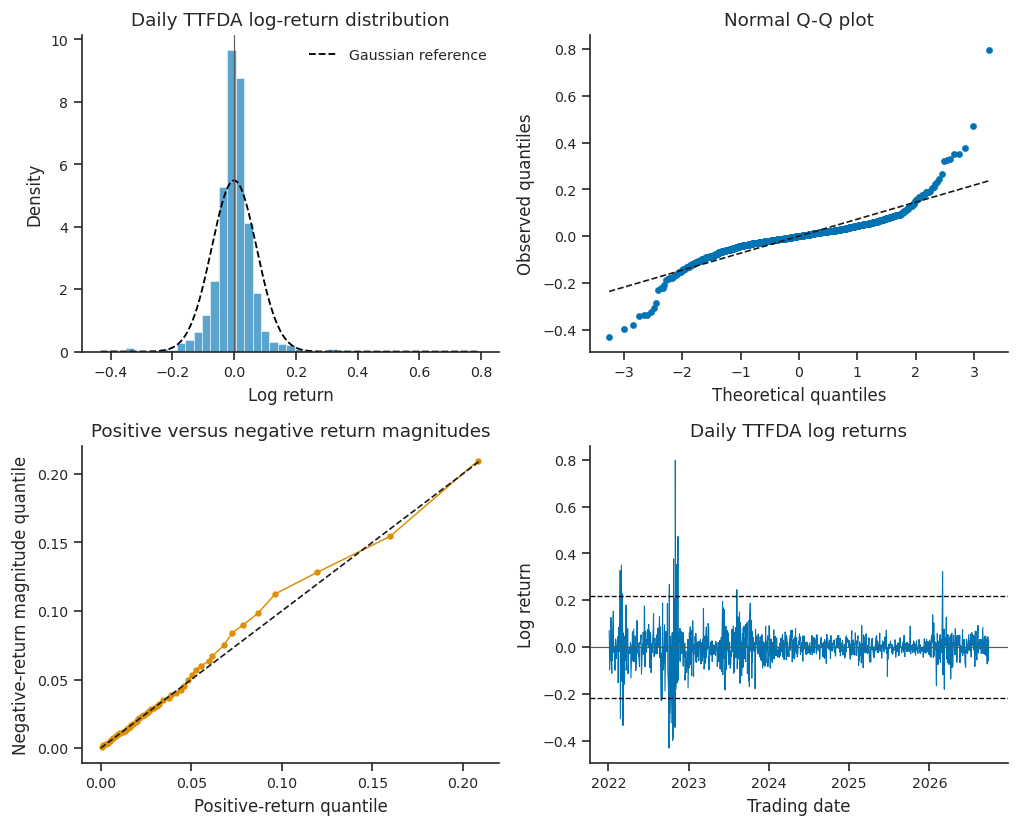

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(8.6, 7.0))

# Distribution with a fitted Gaussian reference.
sns.histplot(
    log_returns,
    bins=45,
    stat="density",
    color=sns.color_palette("colorblind")[0],
    alpha=0.65,
    edgecolor="white",
    linewidth=0.3,
    ax=axes[0, 0],
)
return_grid = np.linspace(log_returns.min(), log_returns.max(), 500)
axes[0, 0].plot(
    return_grid,
    normal_reference.pdf(return_grid),
    color="black",
    linestyle="--",
    linewidth=1.1,
    label="Gaussian reference",
)
axes[0, 0].axvline(0, color="0.35", linewidth=0.7)
axes[0, 0].set_title("Daily TTFDA log-return distribution")
axes[0, 0].set_xlabel("Log return")
axes[0, 0].set_ylabel("Density")
axes[0, 0].legend(frameon=False)

# Normal Q-Q plot.
qq_theoretical, qq_ordered = stats.probplot(
    log_returns, dist="norm", fit=False
)
sns.scatterplot(
    x=qq_theoretical,
    y=qq_ordered,
    s=14,
    color=sns.color_palette("colorblind")[0],
    edgecolor=None,
    ax=axes[0, 1],
)
qq_line = np.array([qq_theoretical.min(), qq_theoretical.max()])
axes[0, 1].plot(
    qq_line, normal_reference.ppf(stats.norm.cdf(qq_line)), "k--", linewidth=1
)
axes[0, 1].set_title("Normal Q-Q plot")
axes[0, 1].set_xlabel("Theoretical quantiles")
axes[0, 1].set_ylabel("Observed quantiles")

# Positive and negative tail magnitudes should coincide under symmetry.
positive = np.sort(log_returns[log_returns > 0].to_numpy())
negative = np.sort(-log_returns[log_returns < 0].to_numpy())
quantile_grid = np.linspace(0.02, 0.98, 49)
positive_quantiles = np.quantile(positive, quantile_grid)
negative_quantiles = np.quantile(negative, quantile_grid)
upper = max(positive_quantiles.max(), negative_quantiles.max())
axes[1, 0].plot(
    positive_quantiles,
    negative_quantiles,
    marker="o",
    markersize=2.8,
    linewidth=0.9,
    color=sns.color_palette("colorblind")[1],
)
axes[1, 0].plot([0, upper], [0, upper], "k--", linewidth=1)
axes[1, 0].set_title("Positive versus negative return magnitudes")
axes[1, 0].set_xlabel("Positive-return quantile")
axes[1, 0].set_ylabel("Negative-return magnitude quantile")

# Return time series and a simple three-standard-deviation reference band.
sns.lineplot(
    data=returns,
    x="TrdDate",
    y="log_return",
    linewidth=0.65,
    color=sns.color_palette("colorblind")[0],
    ax=axes[1, 1],
)
std = log_returns.std(ddof=1)
axes[1, 1].axhline(0, color="0.35", linewidth=0.7)
axes[1, 1].axhline(3 * std, color="black", linestyle="--", linewidth=0.8)
axes[1, 1].axhline(-3 * std, color="black", linestyle="--", linewidth=0.8)
axes[1, 1].set_title("Daily TTFDA log returns")
axes[1, 1].set_xlabel("Trading date")
axes[1, 1].set_ylabel("Log return")
axes[1, 1].xaxis.set_major_locator(mdates.YearLocator())
axes[1, 1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.tight_layout()
fig.savefig(figure_dir / "ttfda_return_diagnostics.png", bbox_inches="tight")
plt.show()